In [26]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [ ]:
activation_func = "none"

batch_size = 256

trainset = datasets.MNIST("./dataset/", train=True, transform = transforms.ToTensor(), download = True)
#dataloader = torch.utils.data.DataLoader(trainset, batch_size = batch_size, shuffle = True, num_workers = 2)

testset = datasets.MNIST("./dataset/", train=False, transform = transforms.ToTensor(), download =   True)
#testloader = torch.utils.data.DataLoader(testset, batch_size = batch_size, shuffle = False, num_workers = 2)

dataset = torch.utils.data.ConcatDataset([trainset, testset])
dataloader = torch.utils.data.DataLoader(
    dataset,
    batch_size = 256,
    shuffle = True
)

tensor_to_img = transforms.ToPILImage()

In [ ]:
class SAE(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder_layer_1 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(28 * 28, 500),
            nn.ReLU(),
        )

        self.decoder_layer_1 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(500, 28 * 28),
        )

        self.encoder_layer_2 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(500, 500),
            nn.ReLU(),
        )

        self.decoder_layer_2 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(500, 500),
            nn.ReLU(),
        )

        self.encoder_layer_3 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(500, 2000),
            nn.ReLU(),
        )

        self.decoder_layer_3 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(2000, 500),
            nn.ReLU(),
        )

        self.encoder_layer_4 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(2000, 10),
        )

        self.decoder_layer_4 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(10, 2000),
            nn.ReLU(),
        )

    def forward(self, x):
        encoded = self.encoder_layer_4(
                    self.encoder_layer_3(
                        self.encoder_layer_2(
                            self.encoder_layer_1(x)
                        )
                    )
                )

        decoded = self.decoder_layer_1(
                    self.decoder_layer_2(
                        self.decoder_layer_3(
                            self.decoder_layer_4(encoded)
                        )
                    )
                )
        
        return decoded

# SAE Training

## Pretraining
Greedy layer-wise training

In [ ]:
model = SAE()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Pretraining
pretrain_epochs = 200

# Pretrain layer 1
loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_1.parameters()) + 
    list(model.decoder_layer_1.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

model.train()
for epoch in range(pretrain_epochs):
    batch_losses = []
    
    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)
        e1 = model.encoder_layer_1(images)
        e1_reconstructed = model.decoder_layer_1(e1)
        loss = loss_function(e1_reconstructed, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 1: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre1")

        print(f"Best Pretrain 1 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")

# Pretrain layer 2

model.load_state_dict(torch.load("./models/" + activation_func + "/pre1", weights_only=True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_2.parameters()) + 
    list(model.decoder_layer_2.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()

for epoch in range(pretrain_epochs):
    batch_losses = []

    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)

        with torch.no_grad():
            e1 = model.encoder_layer_1(images)
        
        e2 = model.encoder_layer_2(e1)
        e1_reconstructed = model.decoder_layer_2(e2)

        loss = loss_function(e1_reconstructed, e1)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 2: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre2")

        print(f"Best Pretrain 2 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


# Pretrain layer 3

model.load_state_dict(torch.load("./models/" + activation_func + "/pre2", weights_only=True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_3.parameters()) + 
    list(model.decoder_layer_3.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()
model.encoder_layer_2.eval()

for epoch in range(pretrain_epochs):
    batch_losses = []

    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)

        with torch.no_grad():
            e1 = model.encoder_layer_1(images)
            e2 = model.encoder_layer_2(e1)
        
        e3 = model.encoder_layer_3(e2)
        e2_reconstructed = model.decoder_layer_3(e3)

        loss = loss_function(e2_reconstructed, e2)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 3: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre3")

        print(f"Best Pretrain 3 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


# Pretrain layer 4

model.load_state_dict(torch.load("./models/" + activation_func + "/pre3", weights_only=True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_4.parameters()) + 
    list(model.decoder_layer_4.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()
model.encoder_layer_2.eval()
model.encoder_layer_3.eval()

for epoch in range(pretrain_epochs):
    batch_losses = []

    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)

        with torch.no_grad():
            e1 = model.encoder_layer_1(images)
            e2 = model.encoder_layer_2(e1)
            e3 = model.encoder_layer_3(e2)
        
        e4 = model.encoder_layer_4(e3)
        e3_reconstructed = model.decoder_layer_4(e4)

        loss = loss_function(e3_reconstructed, e3)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 4: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre4")

        print(f"Best Pretrain 4 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")

Pretrain 1: Epoch 1/200, Loss: 0.112404
Best Pretrain 1 Epoch: 0/200, Loss: 0.112404
Pretrain 1: Epoch 2/200, Loss: 0.068610
Best Pretrain 1 Epoch: 1/200, Loss: 0.068610
Pretrain 1: Epoch 3/200, Loss: 0.063472
Best Pretrain 1 Epoch: 2/200, Loss: 0.063472
Pretrain 1: Epoch 4/200, Loss: 0.057954
Best Pretrain 1 Epoch: 3/200, Loss: 0.057954
Pretrain 1: Epoch 5/200, Loss: 0.053271
Best Pretrain 1 Epoch: 4/200, Loss: 0.053271
Pretrain 1: Epoch 6/200, Loss: 0.049573
Best Pretrain 1 Epoch: 5/200, Loss: 0.049573
Pretrain 1: Epoch 7/200, Loss: 0.046580
Best Pretrain 1 Epoch: 6/200, Loss: 0.046580
Pretrain 1: Epoch 8/200, Loss: 0.044139
Best Pretrain 1 Epoch: 7/200, Loss: 0.044139
Pretrain 1: Epoch 9/200, Loss: 0.042112
Best Pretrain 1 Epoch: 8/200, Loss: 0.042112
Pretrain 1: Epoch 10/200, Loss: 0.040397
Best Pretrain 1 Epoch: 9/200, Loss: 0.040397
Pretrain 1: Epoch 11/200, Loss: 0.038897
Best Pretrain 1 Epoch: 10/200, Loss: 0.038897
Pretrain 1: Epoch 12/200, Loss: 0.037588
Best Pretrain 1 Epoch

## Finetuning

In [ ]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre4", weights_only=True))

train_epochs = 400

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    model.parameters(),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

model.eval() # deactivate all dropout
for epoch in range(train_epochs):
    batch_losses = []
    
    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)
        reconstructed = model(images)
        loss = loss_function(reconstructed, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 1: Epoch {epoch+1}/{train_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/finetuned")

        print(f"Best Finetune Epoch: {best_loss[1]}/{train_epochs}, Loss: {best_loss[0]:.6f}")

Pretrain 1: Epoch 1/200, Loss: 0.057141
Best Finetune Epoch: 0/400, Loss: 0.057141
Pretrain 1: Epoch 2/200, Loss: 0.042036
Best Finetune Epoch: 1/400, Loss: 0.042036
Pretrain 1: Epoch 3/200, Loss: 0.036049
Best Finetune Epoch: 2/400, Loss: 0.036049
Pretrain 1: Epoch 4/200, Loss: 0.032930
Best Finetune Epoch: 3/400, Loss: 0.032930
Pretrain 1: Epoch 5/200, Loss: 0.031345
Best Finetune Epoch: 4/400, Loss: 0.031345
Pretrain 1: Epoch 6/200, Loss: 0.030353
Best Finetune Epoch: 5/400, Loss: 0.030353
Pretrain 1: Epoch 7/200, Loss: 0.029610
Best Finetune Epoch: 6/400, Loss: 0.029610
Pretrain 1: Epoch 8/200, Loss: 0.029015
Best Finetune Epoch: 7/400, Loss: 0.029015
Pretrain 1: Epoch 9/200, Loss: 0.028509
Best Finetune Epoch: 8/400, Loss: 0.028509
Pretrain 1: Epoch 10/200, Loss: 0.028056
Best Finetune Epoch: 9/400, Loss: 0.028056
Pretrain 1: Epoch 11/200, Loss: 0.027655
Best Finetune Epoch: 10/400, Loss: 0.027655
Pretrain 1: Epoch 12/200, Loss: 0.027284
Best Finetune Epoch: 11/400, Loss: 0.027284

# Image Reconstruction

## Autoencoder Layer 1


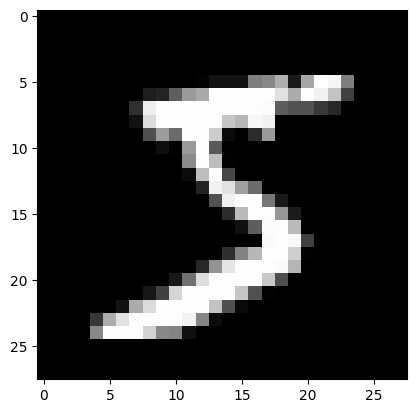

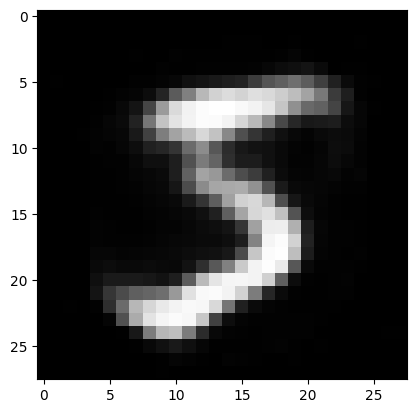

In [ ]:
image_tensor = dataset[0][0]
image = tensor_to_img(image_tensor)
imgplot = plt.imshow(image, cmap = "gray")
plt.show()

model.load_state_dict(torch.load("./models/" + activation_func + "/pre1", weights_only = True))
model.eval()

with torch.no_grad():
    image_tensor = torch.flatten(image_tensor).to(device)

    e1 = model.encoder_layer_1(image_tensor)
    e1_reconstructed = model.decoder_layer_1(e1)

e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

image_reconstructed = tensor_to_img(e1_reconstructed)

# To view it:
imgplot = plt.imshow(image_reconstructed, cmap = "gray")
plt.show()

## Autoencoder Layer 2

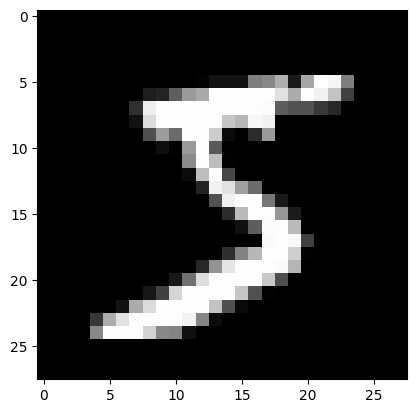

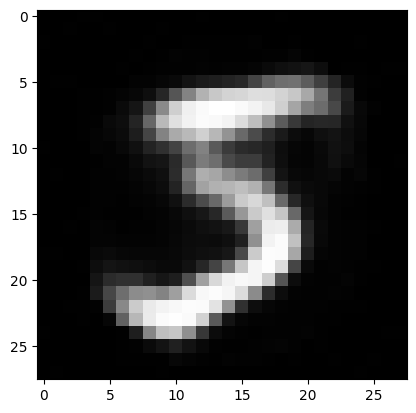

In [ ]:
image_tensor = dataset[0][0]
image = tensor_to_img(image_tensor)
imgplot = plt.imshow(image, cmap = "gray")
plt.show()

model.load_state_dict(torch.load("./models/" + activation_func + "/pre2", weights_only = True))
model.eval()

with torch.no_grad():
    image_tensor = torch.flatten(image_tensor).to(device)

    e1 = model.encoder_layer_1(image_tensor)
    e2 = model.encoder_layer_2(e1)

    e2_reconstructed = model.decoder_layer_2(e2)
    e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

image_reconstructed = tensor_to_img(e1_reconstructed)

imgplot = plt.imshow(image_reconstructed, cmap = "gray")
plt.show()

## Autoencoder Layer 3

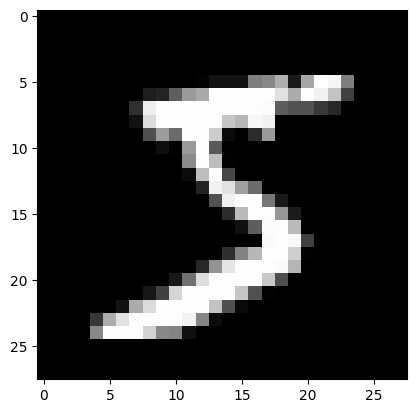

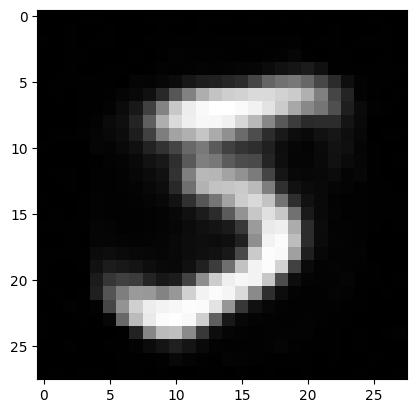

In [ ]:
image_tensor = dataset[0][0]
image = tensor_to_img(image_tensor)
imgplot = plt.imshow(image, cmap = "gray")
plt.show()

model.load_state_dict(torch.load("./models/" + activation_func + "/pre3", weights_only = True))
model.eval()

with torch.no_grad():
    image_tensor = torch.flatten(image_tensor).to(device)

    e1 = model.encoder_layer_1(image_tensor)
    e2 = model.encoder_layer_2(e1)
    e3 = model.encoder_layer_3(e2)

    e3_reconstructed = model.decoder_layer_3(e3)
    e2_reconstructed = model.decoder_layer_2(e3_reconstructed)
    e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

image_reconstructed = tensor_to_img(e1_reconstructed)

imgplot = plt.imshow(image_reconstructed, cmap = "gray")
plt.show()

## Autoencoder Layer 4

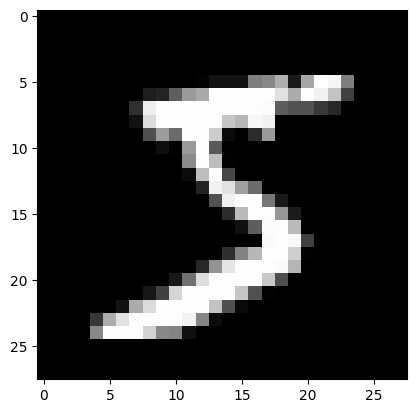

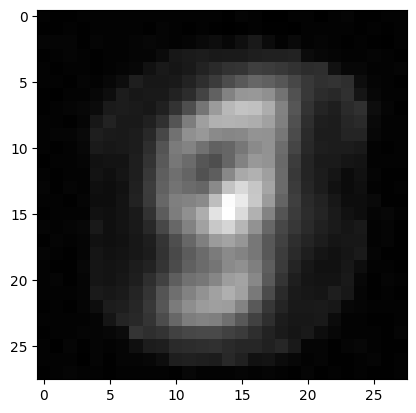

In [ ]:
image_tensor = dataset[0][0]
image = tensor_to_img(image_tensor)
imgplot = plt.imshow(image, cmap = "gray")
plt.show()

model.load_state_dict(torch.load("./models/" + activation_func + "/pre4", weights_only = True))
model.eval()

with torch.no_grad():
    image_tensor = torch.flatten(image_tensor).to(device)

    e1 = model.encoder_layer_1(image_tensor)
    e2 = model.encoder_layer_2(e1)
    e3 = model.encoder_layer_3(e2)
    e4 = model.encoder_layer_4(e3)

    e4_reconstructed = model.decoder_layer_4(e4)
    e3_reconstructed = model.decoder_layer_3(e4_reconstructed)
    e2_reconstructed = model.decoder_layer_2(e3_reconstructed)
    e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

image_reconstructed = tensor_to_img(e1_reconstructed)

imgplot = plt.imshow(image_reconstructed, cmap = "gray")
plt.show()

## Finetuned

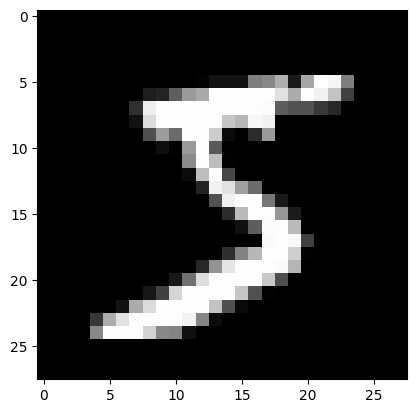

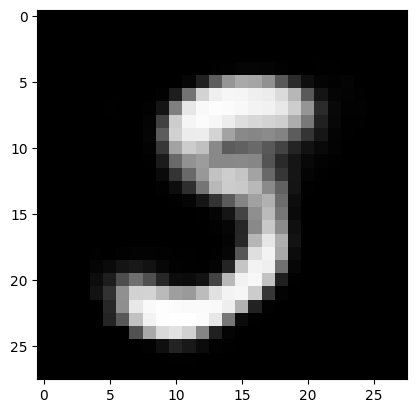

In [ ]:
image_tensor = dataset[0][0]
image = tensor_to_img(image_tensor)
imgplot = plt.imshow(image, cmap = "gray")
plt.show()

model.load_state_dict(torch.load("./models/" + activation_func + "/finetuned", weights_only = True))
model.eval()

with torch.no_grad():
    image_tensor = torch.flatten(image_tensor).to(device)
    reconstructed = model(image_tensor)

reconstructed = torch.unflatten(reconstructed, dim = 0, sizes = (28, 28)).to(device)

image_reconstructed = tensor_to_img(reconstructed)

imgplot = plt.imshow(image_reconstructed, cmap = "gray")
plt.show()

# Clustering